# Визуализация данных с использованием библиотеки Seaborn

**Отчёт о выполнении лабораторной работы**

| Поле                 | Значение                         |
|----------------------|----------------------------------|
| Выполнил:            | *Бахтагареев М.Р., ИСУ24-1*      |
| Проверил преподаватель: | *Пяткова Т.В.*                   |
| Дисциплина:          | *Прикладная визуализация данных* |


## Введение

**Seaborn** — библиотека визуализации данных поверх **matplotlib**, интегрированная с **pandas**.
Она предоставляет высокоуровневый интерфейс для построения статистических графиков:
гистограмм (`histplot`), коробчатых диаграмм (`boxplot`), точечных графиков (`scatterplot`),
матриц диаграмм рассеяния (`pairplot`), тепловых карт (`heatmap`), графиков счётчика (`countplot`)
и скрипичных диаграмм (`violinplot`).

В работе используются три классических набора данных, встроенных в Seaborn:

| Набор данных | Объекты | Описание |
|---|---|---|
| `tips` | 244 чека ресторана | сумма счёта, чаевые, пол, курение, день, время, размер компании |
| `iris` | 150 цветков ириса | длины/ширины чашелистика и лепестка, вид (3 вида) |
| `titanic` | 891 пассажир «Титаника» | пол, возраст, класс, выживание и др. |

**Структура работы:** Задание 1 — базовые графики по `tips`; Задание 2 — взаимосвязи признаков `iris`
(`pairplot`, тепловая карта корреляции); Задание 3 — категориальные данные `titanic`
(`countplot`, `violinplot`/`boxplot`). В конце каждого задания — краткие выводы, в конце ноутбука — общие.

> **Примечание.** `sns.load_dataset(...)` при первом запуске скачивает данные из интернета
> и кэширует их локально (в `~/seaborn-data`). Для работы офлайн выполните один раз онлайн-запуск,
> либо сохраните таблицы: `tips.to_csv("tips.csv")` и загрузите их через `pd.read_csv(...)`.

### Настройка окружения

Импортируем библиотеки и зададим единый стиль всех графиков: `whitegrid` (белый фон со светлой сеткой)
и палитра `deep` — аккуратный учебный стиль. Заодно зафиксируем размеры шрифтов заголовков и подписей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Единый стиль для всех графиков работы
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120      # чёткость изображений в ноутбуке
plt.rcParams["axes.titlesize"] = 14   # размер заголовка графика
plt.rcParams["axes.labelsize"] = 12   # размер подписей осей

print("Версии библиотек:")
print(f"  pandas     = {pd.__version__}")
print(f"  seaborn    = {sns.__version__}")
print(f"  matplotlib = {plt.matplotlib.__version__}")

Версии библиотек:
  pandas     = 3.0.1
  seaborn    = 0.13.2
  matplotlib = 3.10.8


---
## Задание 1. Построение базовых графиков (набор данных Tips)

Требуется построить:
1. **гистограмму** распределения чаевых (`tip`);
2. **коробчатую диаграмму** (boxplot) сравнения чаевых по дням недели (`day`);
3. **точечный график** зависимости чаевых от суммы счёта (`total_bill`).

Для каждого графика настраиваются подписи осей, заголовок и легенда.

### 1.1. Загрузка данных

Набор данных `tips` загружается встроенной функцией `sns.load_dataset`. Каждая строка — один чек
ресторана: `total_bill` — сумма счёта (USD), `tip` — чаевые, `sex` и `smoker` — пол и «курительность»
официант-клиента, `day` и `time` — день недели и время приёма пищи, `size` — число человек за столом.

In [2]:
# Загрузка набора данных Tips (встроен в seaborn)
tips = sns.load_dataset("tips")

print(f"Размер таблицы: {tips.shape[0]} строк x {tips.shape[1]} столбца")
tips.head()

Размер таблицы: 244 строк x 7 столбца


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
# Первичный анализ: типы данных, пропуски и описательные статистики
tips.info()
display(tips.describe().round(2))

# Русские подписи категорий — для читаемых легенд и осей
tips["day_ru"] = tips["day"].map({
    "Thur": "Четверг", "Fri": "Пятница", "Sat": "Суббота", "Sun": "Воскресенье",
})
tips["time_ru"] = tips["time"].map({"Lunch": "Обед", "Dinner": "Ужин"})
tips[["day_ru", "time_ru"]].value_counts().head(8)

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


day_ru       time_ru
Суббота      Ужин       87
Воскресенье  Ужин       76
Четверг      Обед       61
Пятница      Ужин       12
             Обед        7
Четверг      Ужин        1
Воскресенье  Обед        0
Суббота      Обед        0
Name: count, dtype: int64

### 1.2. Гистограмма распределения чаевых

Гистограмма показывает частоты попадания чаевых в интервалы («корзины»). Дополнительно строим
ядерную оценку плотности (KDE) и вертикальные линии среднего и медианы — так легче судить
о форме и асимметрии распределения.

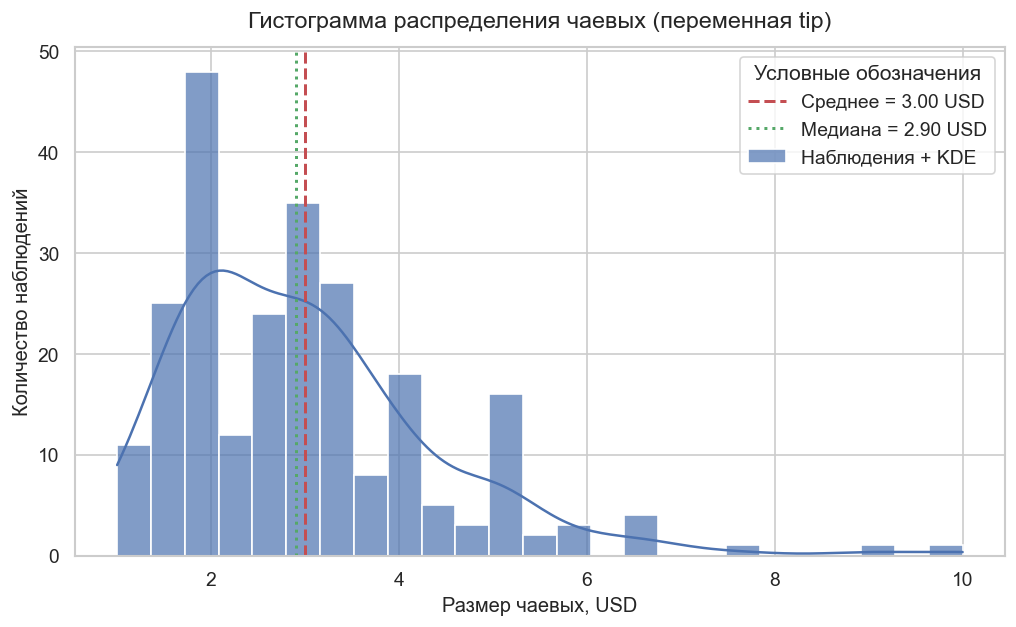

Стандартное отклонение: 1.38 USD; минимум: 1.00; максимум: 10.00


In [24]:
# РИСУНОК: fig_1_1
mean_tip = tips["tip"].mean()
median_tip = tips["tip"].median()

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(
    data=tips, x="tip", bins=25, kde=True,
    color="#4C72B0", alpha=0.7, ax=ax, label="Наблюдения + KDE",
)
ax.axvline(mean_tip, color="#C44E52", ls="--", lw=1.8,
           label=f"Среднее = {mean_tip:.2f} USD")
ax.axvline(median_tip, color="#55A868", ls=":", lw=1.8,
           label=f"Медиана = {median_tip:.2f} USD")

ax.set_title("Гистограмма распределения чаевых (переменная tip)", pad=12)
ax.set_xlabel("Размер чаевых, USD")
ax.set_ylabel("Количество наблюдений")
ax.legend(title="Условные обозначения")
plt.show()


print(f"Стандартное отклонение: {tips['tip'].std():.2f} USD; "
      f"минимум: {tips['tip'].min():.2f}; максимум: {tips['tip'].max():.2f}")

**Наблюдения по гистограмме.** Распределение чаевых правоасимметрично (скошено вправо):
основная масса чаевых лежит в диапазоне 2–4 USD, медиана (2.90 USD) меньше среднего (3.00 USD) —
типичный признак «длинного правого хвоста». Единичные крупные чаевые (до 10 USD) являются выбросами
и тянут среднее вверх, поэтому для описания типичного чаевого корректнее опираться на медиану.

### 1.3. Коробчатая диаграмма: чаевые по дням недели

Boxplot визуализирует медиану, квартили (IQR), «усы» (1.5·IQR) и выбросы — то есть сразу
даёт сравнение уровней и разброса чаевых между четырьмя днями недели.

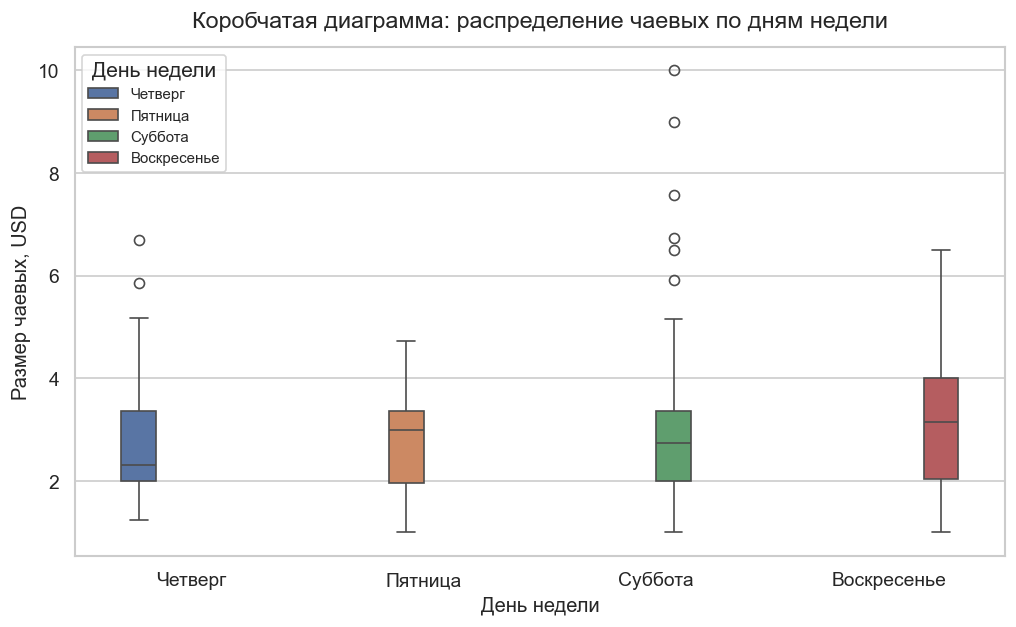

In [5]:
# РИСУНОК: fig_1_2
day_order = ["Четверг", "Пятница", "Суббота", "Воскресенье"]

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(
    data=tips, x="day_ru", y="tip", hue="day_ru",
    order=day_order, hue_order=day_order,
    palette="deep", legend=True, width=0.6, ax=ax,
)
ax.set_title("Коробчатая диаграмма: распределение чаевых по дням недели", pad=12)
ax.set_xlabel("День недели")
ax.set_ylabel("Размер чаевых, USD")
ax.legend(title="День недели", loc="upper left", fontsize=9)
plt.show()

In [6]:
# Числовое подтверждение картины на графике
tips.groupby("day_ru", observed=True)["tip"].agg(
    count="count", mean="mean", median="median", max="max"
).round(2).reindex(day_order)

,count,mean,median,max
day_ru,,,,
Четверг,62,2.77,2.30,6.70
Пятница,19,2.73,3.00,4.73
Суббота,87,2.99,2.75,10.00
Воскресенье,76,3.26,3.15,6.50


**Наблюдения по boxplot.** Воскресенье — самый «доходный» день: медиана (3.15 USD) и среднее
(3.26 USD) чаевых максимальны. Суббота выделяется наибольшим разбросом — растянутый «ящик»,
шесть высоких выбросов и максимум 10 USD; именно там чаевые наименее предсказуемы. Пятница —
наименее загруженный день (всего 19 чеков), поэтому её сравнение с остальными менее надёжно.
В четверг медиана минимальна (2.30 USD), а разброс невелик — чаевые в будни скромнее и стабильнее.

### 1.4. Точечный график: чаевые и сумма счёта

Scatter-график показывает, как размер чаевых `tip` зависит от суммы счёта `total_bill`.
Цветом отмечено время приёма пищи (обед/ужин), маркером — курящий ли клиент,
пунктирной линией — линейный тренд (метод наименьших квадратов).

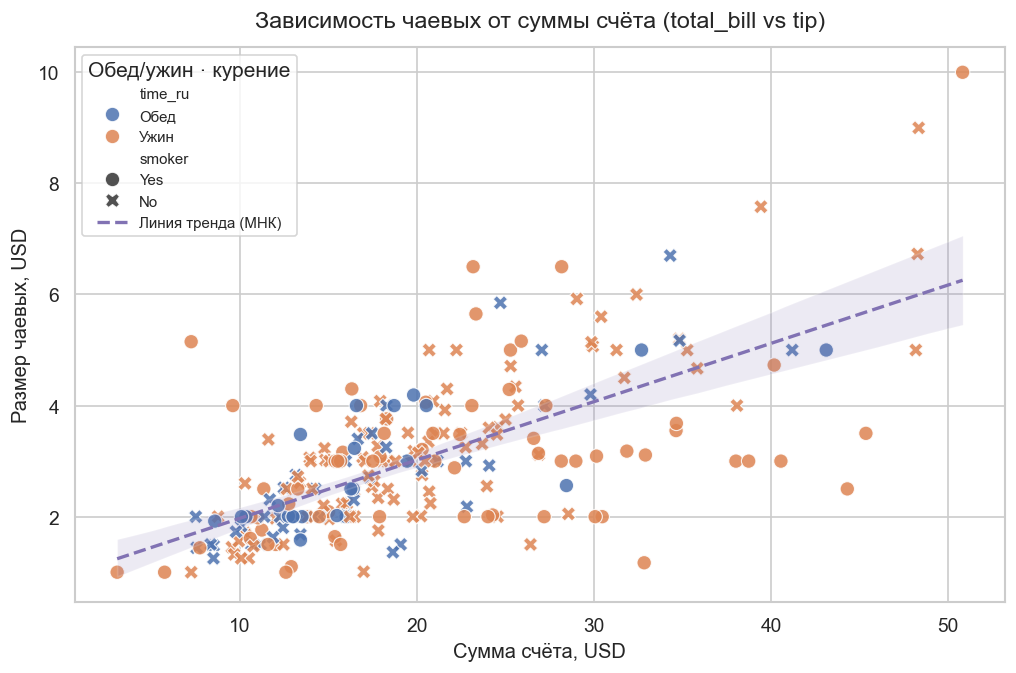

Коэффициент корреляции Пирсона r(total_bill, tip) = 0.676
Коэффициент наклона линейного тренда: 0.105 USD на 1 USD счёта


In [7]:
# РИСУНОК: fig_1_3
corr_bill_tip = tips["total_bill"].corr(tips["tip"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=tips, x="total_bill", y="tip",
    hue="time_ru", style="smoker", s=75, alpha=0.85, ax=ax,
)
sns.regplot(
    data=tips, x="total_bill", y="tip", scatter=False,
    color="#8172B3", line_kws={"ls": "--", "lw": 2}, label="Линия тренда (МНК)", ax=ax,
)

ax.set_title("Зависимость чаевых от суммы счёта (total_bill vs tip)", pad=12)
ax.set_xlabel("Сумма счёта, USD")
ax.set_ylabel("Размер чаевых, USD")
ax.legend(title="Обед/ужин · курение", loc="upper left", fontsize=9)
plt.show()

print(f"Коэффициент корреляции Пирсона r(total_bill, tip) = {corr_bill_tip:.3f}")
print(f"Коэффициент наклона линейного тренда: "
      f"{np.polyfit(tips['total_bill'], tips['tip'], 1)[0]:.3f} USD на 1 USD счёта")

**Наблюдения по scatter-графику.** Связь между суммой счёта и чаевыми **положительная и умеренно
сильная**: r ≈ 0.68, наклон тренда ≈ 0.105 — на каждый дополнительный доллар счёта чаевые
в среднем растут примерно на 10 центов. Точки с ростом счёта сильнее разбрасываются вокруг линии
(гетероскедастичность): при крупных счетах «щедрость» менее предсказуема. По времени приёма пищи
явного разделения нет — обеденные чаевые при малых счетах лишь немного компактнее ужинных.

### Выводы по заданию 1

1. Средние чаевые — 3.00 USD, медиана — 2.90 USD; распределение правоасимметрично, с выбросами до 10 USD.
2. Чаевые в выходные дни (Сб, Вс) систематически выше и разнообразнее, чем в будни; пятница — «тихий» день.
3. Чаевые растут вместе со счётом (r ≈ 0.68, ≈ +0.105 USD на 1 USD счёта), но предсказать точную сумму сложно — разброс увеличивается с ростом счёта.

---
## Задание 2. Исследование взаимосвязей между переменными (набор данных Iris)

Требуется:
1. построить **параметрические графики** (`pairplot`) взаимосвязи размеров лепестков и чашелистиков
   для трёх видов ирисов;
2. построить **тепловую карту корреляции** количественных переменных;
3. проинтерпретировать визуализации, отметив интересные зависимости и аномалии.

In [8]:
# Загрузка набора данных Iris
iris = sns.load_dataset("iris")

print(f"Размер таблицы: {iris.shape[0]} строк x {iris.shape[1]} столбца")
print(iris["species"].value_counts().to_string())
display(iris.groupby("species", observed=True).mean().round(2))

# Русские названия признаков — попадут в подписи осей pairplot и тепловой карты
iris_ru = iris.rename(columns={
    "sepal_length": "Длина чашелистика, см",
    "sepal_width":  "Ширина чашелистика, см",
    "petal_length": "Длина лепестка, см",
    "petal_width":  "Ширина лепестка, см",
})
iris_ru.head()

Размер таблицы: 150 строк x 5 столбца
species
setosa        50
versicolor    50
virginica     50


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


,"Длина чашелистика, см","Ширина чашелистика, см","Длина лепестка, см","Ширина лепестка, см",species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 2.1. Матрица диаграмм рассеяния (pairplot)

`pairplot` строит все попарные scatter-графики количественных признаков (на диагонали — распределения
каждого признака), раскрашивая точки по виду ириса. Это «параметрический» обзор всех взаимосвязей
между размерами лепестков и чашелистиков сразу.

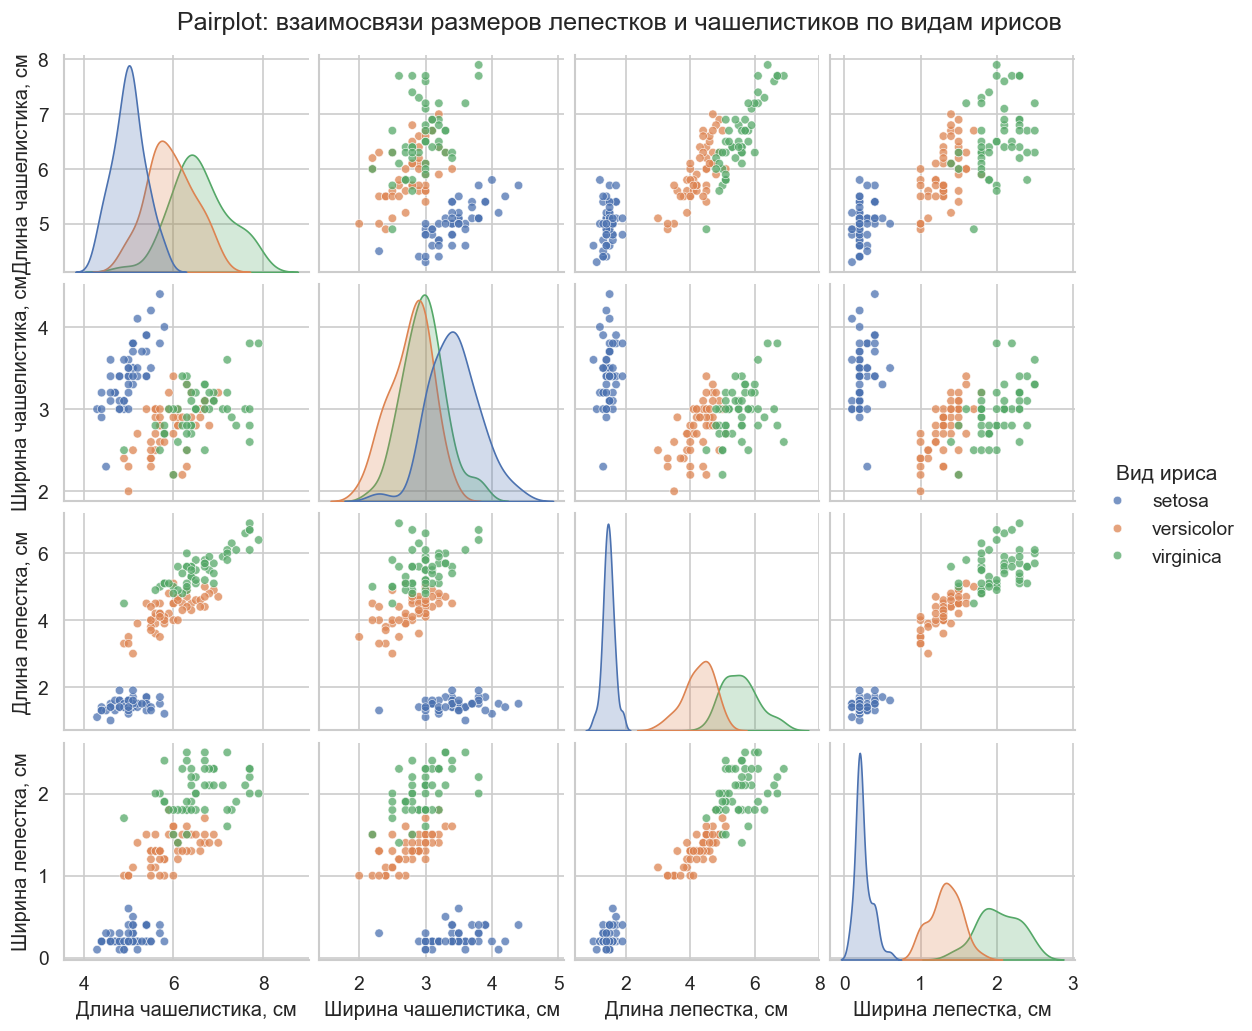

In [9]:
# РИСУНОК: fig_2_1
g = sns.pairplot(
    iris_ru, hue="species", height=2.1, aspect=1.1,
    plot_kws={"s": 26, "alpha": 0.75}, diag_kind="kde",
)
g.figure.suptitle("Pairplot: взаимосвязи размеров лепестков и чашелистиков по видам ирисов",
                  y=1.02, fontsize=15)
g._legend.set_title("Вид ириса")
plt.show()

**Наблюдения по pairplot.**
- **Iris setosa линейно отделима** от двух других видов практически по любой паре признаков —
  в первую очередь по лепесткам: на графиках «длина × ширина лепестка» её кластер стоит особняком.
- **Versicolor и virginica частично перекрываются**, но по паре «длина/ширина лепестка» разделяются
  почти без ошибок — лепестки являются наиболее информативными признаками для классификации.
- Внутри каждого вида размеры лепестка и чашелистика связаны **сильной положительной корреляцией**
  (облака вытянуты вдоль диагонали), тогда как на объединённой выборке ширина чашелистика
  ведёт себя «аномально»: между видами она почти не различается, и общая зависимость размывается.
- Диагональные KDE подтверждают: у `setosa` ширина чашелистика заметно больше, а все лепестковые
  признаки — существенно меньше, чем у остальных видов.

### 2.2. Тепловая карта корреляции

Считаем матрицу корреляций Пирсона четырёх количественных признаков и отображаем её тепловой картой:
красный — положительная связь, синий — отрицательная; в ячейках подписаны коэффициенты.

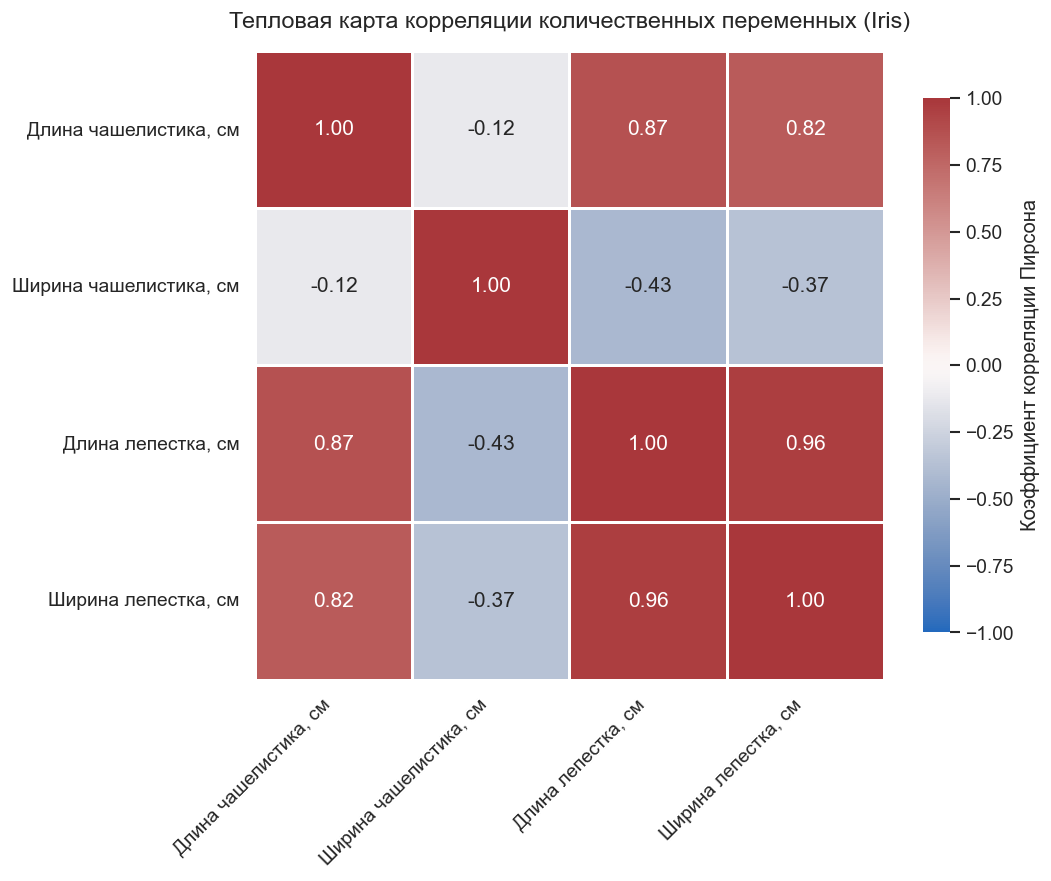

,"Длина чашелистика, см","Ширина чашелистика, см","Длина лепестка, см","Ширина лепестка, см"
"Длина чашелистика, см",1.000,-0.118,0.872,0.818
"Ширина чашелистика, см",-0.118,1.000,-0.428,-0.366
"Длина лепестка, см",0.872,-0.428,1.000,0.963
"Ширина лепестка, см",0.818,-0.366,0.963,1.000


In [17]:
# РИСУНОК: fig_2_2
corr_matrix = iris_ru.drop(columns=["species"]).corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8.5, 6.8))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.8, linecolor="white",
    cbar_kws={"label": "Коэффициент корреляции Пирсона", "shrink": 0.85}, ax=ax,
)
ax.set_title("Тепловая карта корреляции количественных переменных (Iris)", pad=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

corr_matrix.round(3)

**Наблюдения по тепловой карте.**
- Самая сильная связь в данных — **«длина лепестка × ширина лепестка» (r ≈ 0.96)**: признаки
  фактически дублируют друг друга (мультиколлинеарность) — для моделей это избыточность.
- Сильные положительные корреляции у лепестков и с длиной чашелистика (r ≈ 0.82–0.87).
- **Аномалия:** длина и ширина чашелистика на полной выборке практически не коррелируют
  (r ≈ −0.12), а ширина чашелистика с лепестковыми признаками связана **отрицательно** (r ≈ −0.31…−0.43).
  Это «ирисовый парадокс»: внутри каждого вида связь чашелистика с лепестками положительная,
  но из-за межвидовых различий средних на смешанных данных знак корреляции инвертируется
  (эффект Симпсона).
- Вывод для практики: визуальный обзор (`pairplot`) + корреляционная матрица стоит делать **до**
  моделирования — они выявляют и полезные, и «ловушечные» связи.

### Выводы по заданию 2

1. `pairplot` показал линейную отделимость `setosa` и высокую разделяющую силу лепестковых признаков для `versicolor`/`virginica`.
2. Максимальная корреляция — «длина лепестка × ширина лепестка» (r ≈ 0.96); лепестковые признаки мультиколлинеарны.
3. Отмечена аномалия (эффект Симпсона): отрицательные межгрупповые корреляции ширины чашелистика при положительных внутригрупповых связях.

---
## Задание 3. Визуализация категориальных данных (набор данных Titanic)

Требуется:
1. построить **countplot** распределения выживших по полу;
2. построить **violinplot/boxplot** распределения возраста выживших и погибших;
3. сделать визуализацию информативной и читабельной (подписи, легенды, аннотации).

> В столбце `age` есть пропуски (177 из 891) — для возрастных графиков они исключаются (`dropna`),
> что будет отмечено в интерпретации.

In [11]:
# Загрузка набора данных Titanic
titanic = sns.load_dataset("titanic")

# Читаемые категории для легенд
titanic["status"] = titanic["survived"].map({0: "Погибшие", 1: "Выжившие"})
titanic["sex_ru"] = titanic["sex"].map({"male": "Мужчины", "female": "Женщины"})

print(f"Размер таблицы: {titanic.shape[0]} строк x {titanic.shape[1]} столбца")
print(f"Пропусков в age: {titanic['age'].isna().sum()} из {len(titanic)}")

survival_table = (
    titanic.pivot_table(index="sex_ru", columns="status", values="survived",
                        aggfunc="count", observed=True)
    .reindex(columns=["Погибшие", "Выжившие"])
)
survival_table["Доля выживших, %"] = (
    100 * survival_table["Выжившие"] / survival_table.sum(axis=1)
).round(1)
survival_table

Размер таблицы: 891 строк x 17 столбца
Пропусков в age: 177 из 891


status,Погибшие,Выжившие,"Доля выживших, %"
sex_ru,,,
Женщины,81,233,74.2
Мужчины,468,109,18.9


### 3.1. Countplot: пассажиры по полу и исходу

`countplot` — гистограмма по категориям: столбцы = число пассажиров каждого пола, раскраска по `hue` —
исход (погиб/выжил). Подписи над столбцами делают график самодостаточным.

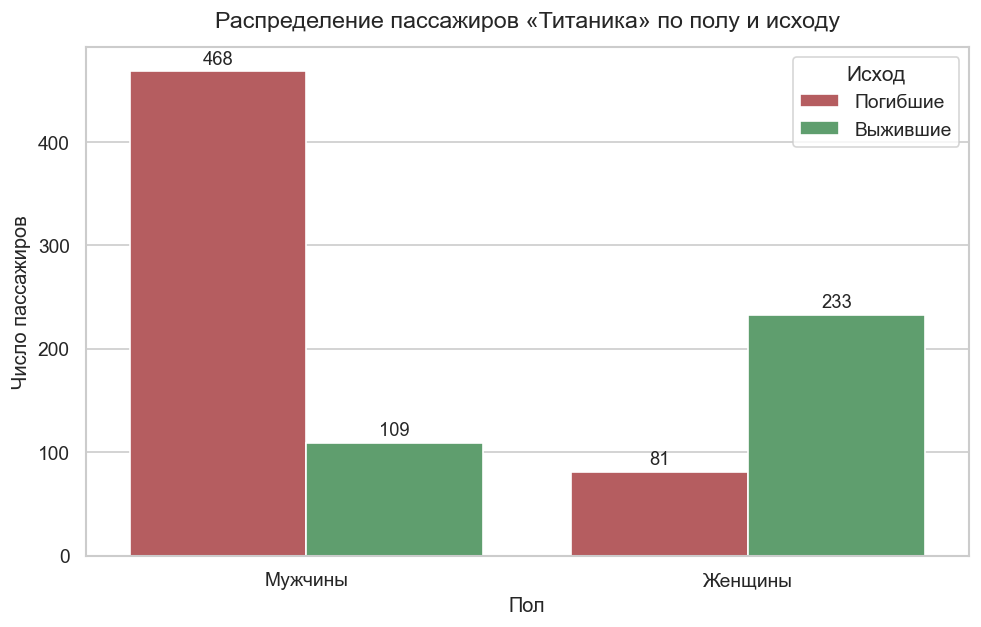

In [12]:
# РИСУНОК: fig_3_1
fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.countplot(
    data=titanic, x="sex_ru", hue="status",
    palette={"Погибшие": "#C44E52", "Выжившие": "#55A868"}, ax=ax,
)
for container in ax.containers:            # подписи значений над столбцами
    ax.bar_label(container, fontsize=11, padding=2)

ax.set_title("Распределение пассажиров «Титаника» по полу и исходу", pad=12)
ax.set_xlabel("Пол")
ax.set_ylabel("Число пассажиров")
ax.legend(title="Исход")
plt.show()

**Наблюдения по countplot.** Пассажиров-мужчин было заметно больше (577 против 314 женщин), однако
исходы противоположны: среди женщин выжили **74.2 %** (233 из 314), среди мужчин — лишь **18.9 %**
(109 из 577). Общая выживаемость — 38.4 %. Перевёрнутое соотношение столбцов наглядно фиксирует
действие правила «женщины и дети — первыми» при эвакуации.

### 3.2. Возраст выживших и погибших: violinplot и boxplot

Слева — `violinplot` (оценка плотности возраста, разделение по полу, квартили внутри),
справа — `boxplot` (медиана, квартили, выбросы). Возраст известен не у всех пассажиров,
поэтому перед построением строки с пропусками исключаются.

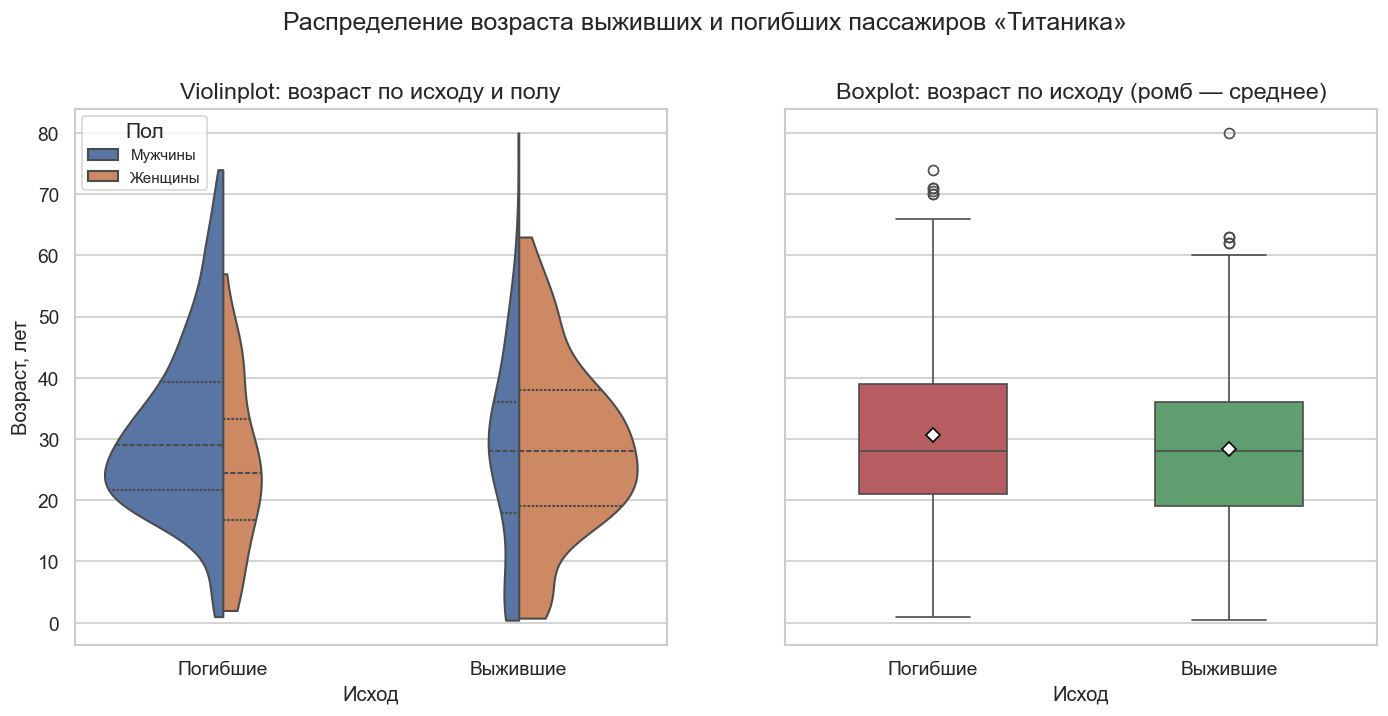

,count,mean,median,min,max
status,,,,,
Погибшие,424,30.63,28.0,1.00,74.0
Выжившие,290,28.34,28.0,0.42,80.0


In [13]:
# РИСУНОК: fig_3_2
titanic_age = titanic.dropna(subset=["age"]).copy()
status_order = ["Погибшие", "Выжившие"]
palette_status = {"Погибшие": "#C44E52", "Выжившие": "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)

# Слева: скрипичная диаграмма с разделением по полу
sns.violinplot(
    data=titanic_age, x="status", y="age", hue="sex_ru", order=status_order,
    split=True, inner="quartile", density_norm="count",
    palette="deep", cut=0, ax=axes[0],
)
axes[0].set_title("Violinplot: возраст по исходу и полу")
axes[0].set_xlabel("Исход")
axes[0].set_ylabel("Возраст, лет")
axes[0].legend(title="Пол", loc="upper left", fontsize=9)

# Справа: коробчатая диаграмма по исходам
sns.boxplot(
    data=titanic_age, x="status", y="age", hue="status", order=status_order,
    palette=palette_status, legend=False, width=0.5, showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
    ax=axes[1],
)
axes[1].set_title("Boxplot: возраст по исходу (ромб — среднее)")
axes[1].set_xlabel("Исход")
axes[1].set_ylabel("Возраст, лет")

fig.suptitle("Распределение возраста выживших и погибших пассажиров «Титаника»", fontsize=15, y=1.02)
plt.show()

age_stats = titanic_age.groupby("status", observed=True)["age"].agg(
    count="count", mean="mean", median="median", min="min", max="max"
).round(2).reindex(status_order)
age_stats

**Наблюдения по возрастным графикам.** Медианный возраст выживших и погибших близок
(≈ 28 против ≈ 28 лет), но формы распределений различаются: среди погибших «толще» прослойка
молодых мужчин 20–30 лет, а у выживших заметен **дополнительный купол в детской области**
(0–10 лет) — детей спасали первыми. Средний возраст погибших чуть выше (30.6 против 28.3 лет).
Boxplot подтверждает: медианы почти совпадают, но «нижний хвост» у выживших шире. Важная оговорка:
графики построены по 714 пассажирам с известным возрастом (177 значений пропущены), поэтому
выводы применимы только к этой подвыборке.

---
## Итоговые выводы по работе

1. **Задание 1 (Tips).** Построены гистограмма, boxplot и scatter-график с подписями, заголовками и легендами. Чаевые правоасимметричны (медиана 2.90 < среднего 3.00 USD), в выходные дни выше и разнообразнее, связь со счётом умеренно сильная (r ≈ 0.68, ≈ +0.10 USD на 1 USD счёта).
2. **Задание 2 (Iris).** `pairplot` выявил линейную отделимость вида `setosa` и ключевую роль лепестков; тепловая карта показала мультиколлинеарность лепестковых признаков (r ≈ 0.96) и аномалию — инверсию знака корреляции на смешанной выборке (эффект Симпсона).
3. **Задание 3 (Titanic).** `countplot` и возрастные диаграммы подтвердили правило «женщины и дети первыми»: выжили 74.2 % женщин против 18.9 % мужчин; у выживших выражен детский «купол» плотности возраста; результаты корректны для 714 пассажиров с известным возрастом.
4. **Общий вывод.** Seaborn позволяет быстро строить информативные статистические графики: каждый тип графика отвечает на свой класс вопросов (histplot — форма распределения; boxplot/violinplot — сравнение групп; scatter/pairplot — взаимосвязи; heatmap — корреляции; countplot — состав категорий). Обязательные элементы качества визуализации — подписи осей, заголовки, легенды и аннотации значений.